In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Heart Disease Prediction

## Goal
Predict whether a patient has heart disease (`AHD`: Yes or No) using patient measurements.

## Problem type
Classification, because the target has two possible answers.

## Data
- Source file: Heart.csv (303 patients, 13 features and 1 target)
- Target: `AHD`
- Missing values: `Ca` (4) and `Thal` (2)


## Understanding the Dataset Columns


| Column | Meaning |
|:---|:---|
| **Age** | Age in years |
| **Sex** | 1 = Male, 0 = Female |
| **ChestPain** | Type of chest pain (typical, nontypical, nonanginal, asymptomatic) |
| **RestBP** | Resting blood pressure |
| **Chol** | Cholesterol level |
| **Fbs** | Fasting blood sugar above 120 (1 = Yes, 0 = No) |
| **RestECG** | Resting electrocardiogram result (0, 1, 2) |
| **MaxHR** | Maximum heart rate achieved during the stress test |
| **ExAng** | Exercise-induced angina (1 = Yes, 0 = No) |
| **Oldpeak** | ST depression induced by exercise relative to rest |
| **Slope** | Slope of the peak exercise ST segment (1, 2, 3) |
| **Ca** | Number of major blood vessels visualised by fluoroscopy (0 to 3) |
| **Thal** | Thalassemia test result (normal, fixed defect, reversible defect) |
| **AHD** | Target variable indicating the presence or absence of heart disease (Yes or No) |

### Dataset Overview

- **Total columns:** 14
- **Input features:** 13
- **Target variable:** AHD
- **Problem type:** Binary Classification

The objective of this project is to use patient characteristics and medical test results to develop a machine learning model that predicts whether a patient has heart disease.


## Plan
1. Load and understand the data
2. Explore the data
3. Clean and prepare the data
4. Build a model
5. Test the model and read the results

In [7]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/kefentsemalatji/heart-csv/Heart.csv", 
                 sep=";", 
                 index_col=0, 
                 na_values=["NA"])
print(df.shape)
df.head()

(303, 14)


,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


In [9]:
print(df.dtypes)


Age            int64
Sex            int64
ChestPain     object
RestBP         int64
Chol           int64
Fbs            int64
RestECG        int64
MaxHR          int64
ExAng          int64
Oldpeak      float64
Slope          int64
Ca           float64
Thal          object
AHD           object
dtype: object


## Missingness

In [11]:
print(df.isna().sum())

Age          0
Sex          0
ChestPain    0
RestBP       0
Chol         0
Fbs          0
RestECG      0
MaxHR        0
ExAng        0
Oldpeak      0
Slope        0
Ca           4
Thal         2
AHD          0
dtype: int64


### Missing Values Analysis

The dataset contains missing values in two columns:

- **Ca:** 4 missing values
- **Thal:** 2 missing values

All other columns have zero missing values.

This indicates that the dataset is relatively complete, with only 6 missing values across the 14 variables.

Further data preprocessing will be required to handle the missing values in `Ca` and `Thal` before building machine learning models.

In [12]:
# Fill missing values in Ca using median
df['Ca'] = df['Ca'].fillna(df['Ca'].median())

# Fill missing values in Thal using mode
df['Thal'] = df['Thal'].fillna(df['Thal'].mode()[0])

# Check missing values after handling
print("\nMissing values after handling:")
print(df.isnull().sum())


Missing values after handling:
Age          0
Sex          0
ChestPain    0
RestBP       0
Chol         0
Fbs          0
RestECG      0
MaxHR        0
ExAng        0
Oldpeak      0
Slope        0
Ca           0
Thal         0
AHD          0
dtype: int64


## Exploratory Data Analysis
Which features look different between patients with and without heart disease?

### Summary of the number columns

In [13]:
df.describe().round(1)

,Age,Sex,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca
count,303.0,303.0,303.0,303.0,303.0,303.0,303.0,303.0,303.0,303.0,303.0
mean,54.4,0.7,131.7,246.7,0.1,1.0,149.6,0.3,1.0,1.6,0.7
std,9.0,0.5,17.6,51.8,0.4,1.0,22.9,0.5,1.2,0.6,0.9
min,29.0,0.0,94.0,126.0,0.0,0.0,71.0,0.0,0.0,1.0,0.0
25%,48.0,0.0,120.0,211.0,0.0,0.0,133.5,0.0,0.0,1.0,0.0
50%,56.0,1.0,130.0,241.0,0.0,1.0,153.0,0.0,0.8,2.0,0.0
75%,61.0,1.0,140.0,275.0,0.0,2.0,166.0,1.0,1.6,2.0,1.0
max,77.0,1.0,200.0,564.0,1.0,2.0,202.0,1.0,6.2,3.0,3.0


#### A cholesterol of 564 is very high compared with the median, so that is a possible outlier.

In [16]:
df.groupby("AHD")[["Age", "RestBP", "Chol", "MaxHR", "Oldpeak"]].mean().round(1)

,Age,RestBP,Chol,MaxHR,Oldpeak
AHD,,,,,
No,52.6,129.2,242.6,158.4,0.6
Yes,56.6,134.6,251.5,139.3,1.6


### Category columns
compare the percentage with heart disease in each group

In [17]:
df["target"] = (df["AHD"] == "Yes").astype(int)   # Yes = 1, No = 0

for col in ["Sex", "ChestPain", "ExAng", "Thal", "Ca"]:
    print(df.groupby(col)["target"].mean().round(2))
    print()

Sex
0    0.26
1    0.55
Name: target, dtype: float64

ChestPain
asymptomatic    0.73
nonanginal      0.21
nontypical      0.18
typical         0.30
Name: target, dtype: float64

ExAng
0    0.31
1    0.77
Name: target, dtype: float64

Thal
fixed         0.67
normal        0.23
reversable    0.76
Name: target, dtype: float64

Ca
0.0    0.26
1.0    0.68
2.0    0.82
3.0    0.85
Name: target, dtype: float64



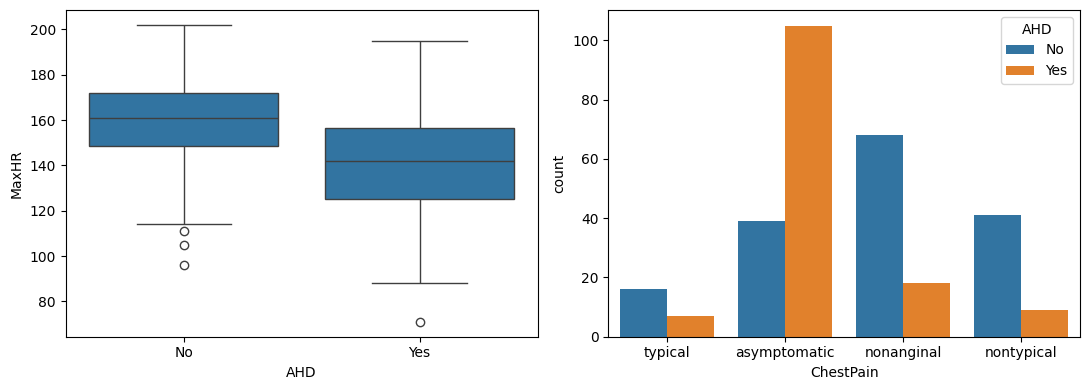

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="AHD", y="MaxHR", ax=ax[0])
sns.countplot(data=df, x="ChestPain", hue="AHD", ax=ax[1])
plt.tight_layout()
plt.show()

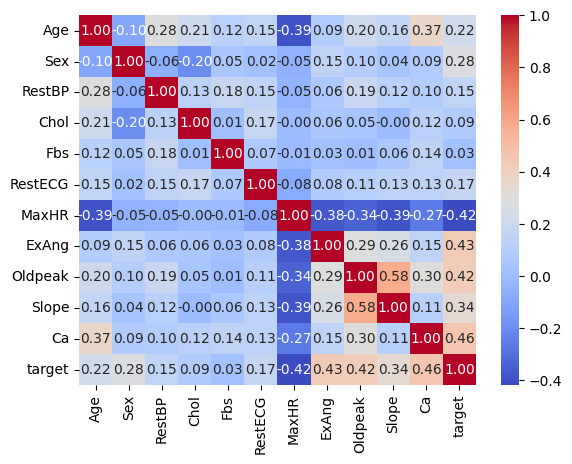

In [19]:
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

The strongest links to heart disease are Ca (0.46), ExAng (0.43), Oldpeak (0.42) and MaxHR (-0.42).

MaxHR is negative. A lower max heart rate goes with more heart disease. Direction matters as much as size.

Chol (0.09) and Fbs (0.03) are very weak. On their own they will not help much.

Oldpeak and Slope are linked to each other (0.58), so they partly carry the same information.



Boxplot: the Yes group has a clearly lower MaxHR (median about 142 vs about 161). The boxes barely overlap in the middle, so this feature separates the groups well.

Count plot: this one is surprising. asymptomatic patients (no obvious chest pain) are the ones most likely to have heart disease, about 105 Yes vs 39 No. A result that goes against your guess is a good thing to write in your markdown notes.

## Data Preparation
1. Separate features (X) from target (y)
2. Split into training and test sets
3. Build a preprocessing pipeline (fill missing values, encode categories, scale numbers)

In [20]:
X = df.drop(columns=["AHD", "target"])
y = df["target"]

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(2), y_test.mean().round(2))

(242, 13) (61, 13)
0.46 0.46


Training set (80%): the model learns from this.

Test set (20%): hidden until the end. It acts like new patients, so it tells us how the model will really perform.

stratify=y keeps the Yes/No balance the same in both sets. The two means printed should be almost equal.

random_state=42 makes your split repeatable.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = ["ChestPain", "Thal", "Slope"]
num_cols = [c for c in X.columns if c not in cat_cols]

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

print(preprocess.fit_transform(X_train).shape)

(242, 20)


## Modelling
Compare a simple model (logistic regression) with a stronger one (random forest) using cross-validation on the training data.

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
}

for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc")
    print(f"{name}: mean AUC = {scores.mean():.3f}, std = {scores.std():.3f}")

Logistic Regression: mean AUC = 0.899, std = 0.043
Random Forest: mean AUC = 0.890, std = 0.038


## Evaluation
Fit the chosen model on the full training set, then score it once on the hidden test set.

In [24]:
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report

best_model = LogisticRegression(max_iter=1000)   # or RandomForestClassifier(n_estimators=300, random_state=42)

final = Pipeline([("prep", preprocess), ("model", best_model)])
final.fit(X_train, y_train)

pred = final.predict(X_test)                 # 0 or 1
prob = final.predict_proba(X_test)[:, 1]     # chance of heart disease

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("ROC AUC:", round(roc_auc_score(y_test, prob), 3))

Accuracy: 0.869
ROC AUC: 0.958


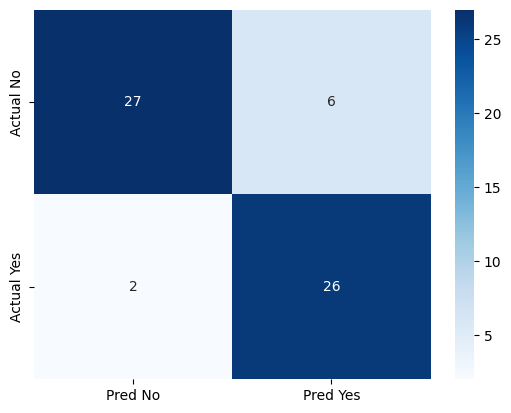

In [25]:
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred No", "Pred Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.show()

The total is 27 + 6 + 2 + 26 = 61, which matches the test set. It splits into 33 healthy and 28 sick patients.

The numbers behind it

Accuracy = (27 + 26) / 61 = 53 / 61 = about 87%
Recall for Yes = 26 / (26 + 2) = about 93%. Of the 28 sick patients, the model caught 26.
Precision for Yes = 26 / (26 + 6) = about 81%. When the model says “sick”, it is right about 4 times out of 5.
Specificity = 27 / (27 + 6) = about 82%. Of the 33 healthy patients, it correctly cleared 27.

What this tells us

The model makes two kinds of mistakes, and they do not cost the same.

2 false negatives (sick patients called healthy) are the dangerous mistakes.
6 false positives (healthy patients flagged) mean extra tests, which is inconvenient but much less harmful.

In [26]:
print(classification_report(y_test, pred, target_names=["No", "Yes"]))

              precision    recall  f1-score   support

          No       0.93      0.82      0.87        33
         Yes       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



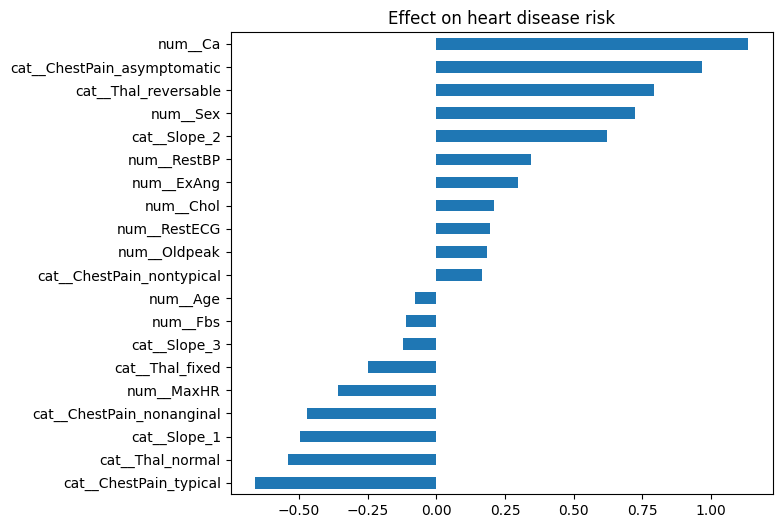

In [27]:
names = final.named_steps["prep"].get_feature_names_out()
coefs = final.named_steps["model"].coef_[0]

imp = pd.Series(coefs, index=names).sort_values()
imp.plot(kind="barh", figsize=(7, 6))
plt.title("Effect on heart disease risk")
plt.show()

## Conclusion
I built a logistic regression model to predict heart disease from 13 patient measurements.
In cross-validation it scored an AUC of 0.90, slightly above a random forest (0.89), so I chose the simpler model.
On 61 unseen patients it reached 87% accuracy and found 26 of the 28 patients with heart disease.
It also raised 6 false alarms for healthy patients.
The strongest signals were the number of blocked vessels (Ca), asymptomatic chest pain and a reversable result on the heart scan.
Limitation: the dataset is small (303 patients), so these results are only an estimate.
The model is for learning and should not be used for real medical decisions.

## Tuning and saving
Try to improve the model fairly, then save it.

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

log_pipe = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000)),
])

In [30]:
from sklearn.model_selection import GridSearchCV

param_grid = {"model__C": [0.01, 0.1, 1, 10, 100]}

grid = GridSearchCV(log_pipe, param_grid, cv=5, scoring="roc_auc")
grid.fit(X_train, y_train)

print("Best setting:", grid.best_params_)
print("Best AUC:", round(grid.best_score_, 3))

Best setting: {'model__C': 0.1}
Best AUC: 0.901


In [31]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score, precision_score

probs = cross_val_predict(log_pipe, X_train, y_train, cv=5, method="predict_proba")[:, 1]

for t in [0.3, 0.4, 0.5, 0.6]:
    pred_t = (probs >= t).astype(int)
    print(t,
          "recall:", round(recall_score(y_train, pred_t), 2),
          "precision:", round(precision_score(y_train, pred_t), 2))

0.3 recall: 0.9 precision: 0.74
0.4 recall: 0.84 precision: 0.82
0.5 recall: 0.77 precision: 0.83
0.6 recall: 0.74 precision: 0.89


In [32]:
import joblib

joblib.dump(grid.best_estimator_, "heart_model.joblib")

loaded = joblib.load("heart_model.joblib")
print(loaded.predict(X_test.head()))

[0 1 0 0 0]
